# Indoor67 — Lower-learning-rate fine-tuning
Resume the original **65.38%** ResNet18 checkpoint, train `layer4` and the classifier at **1e-5 for five epochs**, and retain the best validation accuracy (macro F1 breaks ties). All other preprocessing, optimizer weight decay, batch size, and batch-normalization behavior match notebook 03. This experiment changes the fine-tuning learning rate and training budget; it does not isolate their individual effects.

Use the exact same 4,261/1,066 split and alphabetical mapping of 67 labels. The original checkpoint and results are retained. Test images are excluded. Only the supplied training labels are used; initialization comes from the ImageNet-only model trained in notebook 03.

AI assistance: OpenAI Codex assisted with implementing and executing these experiments and explaining the results. The submitting team must review and understand this code.

In [1]:
from pathlib import Path
import hashlib
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import models, transforms
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from tqdm.auto import tqdm
import sys
import json

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "dataset.py").is_file()
             and (p / "data" / "train.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the repository root or notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.dataset import Indoor67Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.set_num_threads(min(4, torch.get_num_threads()))
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = ROOT / "data"
IMAGE_ROOT = DATA_DIR / "images"
CHECKPOINT_DIR = ROOT / "checkpoints"
EXPERIMENT_DIR = ROOT / "experiments"
CHECKPOINT_DIR.mkdir(exist_ok=True)
EXPERIMENT_DIR.mkdir(exist_ok=True)
SOURCE_PATH = CHECKPOINT_DIR / "resnet18_best.pt"
BEST_PATH = CHECKPOINT_DIR / "resnet18_low_lr_best.pt"
HISTORY_PATH = EXPERIMENT_DIR / "resnet18_low_lr_history.csv"
PROGRESS_PATH = EXPERIMENT_DIR / "resnet18_low_lr_progress.json"
BATCH_SIZE = 32
FINETUNE_EPOCHS = 5
FINETUNE_LR = 1e-5
WEIGHT_DECAY = 1e-4
print("Device:", DEVICE, "| CPU threads:", torch.get_num_threads())

Device: cpu | CPU threads: 4


## 1. Verify the data and source checkpoint
Require the saved split to match the current training manifest. Verify checkpoint provenance, split fingerprint, and label mapping before training.

In [2]:
manifest = pd.read_csv(DATA_DIR / "train.csv", dtype=str).rename(
    columns={"id": "image_id", "file_path": "image_path"}
)
SPLIT_CSV = DATA_DIR / "validation_split.csv"
if not SPLIT_CSV.is_file():
    raise FileNotFoundError("Run notebook 01 to create validation_split.csv first.")
split_df = pd.read_csv(SPLIT_CSV, dtype=str)
keys = ["image_id", "image_path", "label"]
for name, frame in [("manifest", manifest), ("split", split_df)]:
    if frame.empty or not set(keys).issubset(frame.columns):
        raise ValueError(f"Invalid {name}: expected nonempty {keys} columns.")
    if frame[keys].isna().any().any() or frame.image_id.duplicated().any() or frame.image_path.duplicated().any():
        raise ValueError(f"Missing or duplicate values in {name}.")
pd.testing.assert_frame_equal(
    manifest[keys].sort_values("image_id").reset_index(drop=True),
    split_df[keys].sort_values("image_id").reset_index(drop=True),
    obj="Manifest and saved split; rerun notebook 01 if data changed"
)
if "split" not in split_df or split_df["split"].isna().any() or set(split_df["split"]) != {"train", "val"}:
    raise ValueError("Expected only train and val split assignments.")
class_names = sorted(manifest.label.unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
declared = pd.read_csv(DATA_DIR / "classes.csv", dtype=str).label
assert declared.is_unique and set(declared) == set(class_names)
train_df = split_df.loc[split_df["split"] == "train"].reset_index(drop=True)
val_df = split_df.loc[split_df["split"] == "val"].reset_index(drop=True)
assert set(train_df.image_id).isdisjoint(val_df.image_id)
assert set(train_df.label) == set(val_df.label) == set(class_names)
missing = [p for p in split_df.image_path if not (IMAGE_ROOT / p).is_file()]
if missing:
    raise FileNotFoundError(f"Missing {len(missing)} images: {missing[:5]}")
split_sha256 = hashlib.sha256(SPLIT_CSV.read_bytes()).hexdigest()
print(f"Training: {len(train_df):,}; validation: {len(val_df):,}; classes: {len(class_names)}")

Training: 4,261; validation: 1,066; classes: 67


In [3]:
if not SOURCE_PATH.is_file():
    raise FileNotFoundError("Run notebook 03 to create resnet18_best.pt first.")
source_sha256 = hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest()
source_checkpoint = torch.load(SOURCE_PATH, map_location="cpu", weights_only=True)
assert source_checkpoint["architecture"] == "resnet18"
assert source_checkpoint["weights"] == "IMAGENET1K_V1"
assert source_checkpoint["split_sha256"] == split_sha256
assert source_checkpoint["class_to_idx"] == class_to_idx
assert source_checkpoint["class_names"] == class_names
print("Source:", SOURCE_PATH)
print("Source best epoch:", source_checkpoint["best_epoch"])

Source: C:\Users\Spencer\General\daml-aitp\checkpoints\resnet18_best.pt
Source best epoch: {'stage': 'head', 'epoch': 9, 'train_loss': 0.881774361943225, 'train_accuracy': 0.8077915982163811, 'val_loss': 1.317576289176941, 'val_accuracy': 0.6538461538461539, 'val_macro_f1': 0.6505770039483688, 'seconds': 0.11915160005446523}


## 2. Restore the model and unchanged preprocessing
Instantiate the architecture without downloading weights, then load the complete source checkpoint. Keep `layer1`–`layer3` frozen; train `layer4` and the classifier. Batch-normalization running statistics remain fixed. Validation uses deterministic ImageNet resize, center crop, and normalization.

In [4]:
weights = models.ResNet18_Weights.IMAGENET1K_V1
eval_transform = weights.transforms()
assert list(eval_transform.resize_size) == source_checkpoint["resize_size"]
assert list(eval_transform.mean) == list(source_checkpoint["mean"])
assert list(eval_transform.std) == list(source_checkpoint["std"])
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=eval_transform.mean, std=eval_transform.std)
])
train_dataset = Indoor67Dataset(train_df, IMAGE_ROOT, class_to_idx, train_transform)
val_dataset = Indoor67Dataset(val_df, IMAGE_ROOT, class_to_idx, eval_transform)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    pin_memory=DEVICE.type == "cuda", generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=DEVICE.type == "cuda"
)
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model.load_state_dict(source_checkpoint["model_state_dict"])
model = model.to(DEVICE)
for name, parameter in model.named_parameters():
    parameter.requires_grad = name.startswith("layer4.") or name.startswith("fc.")
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=FINETUNE_LR, weight_decay=WEIGHT_DECAY
)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))
print(f"Learning rate: {FINETUNE_LR}; epochs: {FINETUNE_EPOCHS}; batch size: {BATCH_SIZE}")

Trainable parameters: 8428099
Learning rate: 1e-05; epochs: 5; batch size: 32


## 3. Verify the starting score and define checkpoint selection
Epoch 0 is a fresh validation evaluation of the source model. It is included as a candidate so this experiment cannot replace it with a worse model. Save training history after every epoch and a progress record during training. Each run replaces only this experiment's artifacts.

In [5]:
@torch.inference_mode()
def evaluate(loader):
    model.eval()
    total_loss, count = 0.0, 0
    targets_all, predictions_all = [], []
    for images, targets in loader:
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        logits = model(images)
        total_loss += criterion(logits, targets).item() * len(targets)
        count += len(targets)
        targets_all.extend(targets.cpu().tolist())
        predictions_all.extend(logits.argmax(1).cpu().tolist())
    return total_loss / count, np.asarray(targets_all), np.asarray(predictions_all)

def progress(status, **details):
    PROGRESS_PATH.write_text(json.dumps(dict(status=status, **details), indent=2), encoding="utf-8")

history = []
best_score = (-1.0, -1.0)
best_state = None

def record_epoch(epoch, train_loss, train_accuracy, val_loss, targets, predictions, seconds):
    global best_score, best_state
    accuracy = float(accuracy_score(targets, predictions))
    macro_f1 = float(f1_score(targets, predictions, labels=range(len(class_names)), average="macro", zero_division=0))
    row = dict(stage="source" if epoch == 0 else "finetune_low_lr", epoch=epoch,
               train_loss=train_loss, train_accuracy=train_accuracy,
               val_loss=val_loss, val_accuracy=accuracy, val_macro_f1=macro_f1, seconds=seconds)
    history.append(row)
    if (accuracy, macro_f1) > best_score:
        best_score = (accuracy, macro_f1)
        best_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
        checkpoint = dict(source_checkpoint)
        checkpoint.update(
            model_state_dict=best_state, best_epoch=row,
            source_checkpoint=SOURCE_PATH.name, source_checkpoint_sha256=source_sha256,
            source_best_epoch=source_checkpoint["best_epoch"],
            seed=SEED, finetune_lr=FINETUNE_LR, finetune_epochs=FINETUNE_EPOCHS,
            weight_decay=WEIGHT_DECAY, batch_size=BATCH_SIZE,
            trainable_layers=["layer4", "fc"], batchnorm_running_stats="frozen",
            experiment="resnet18_low_lr"
        )
        torch.save(checkpoint, BEST_PATH)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
    progress("epoch_complete", epoch=epoch, **{k: v for k, v in row.items() if k != "epoch"})
    print(f"Epoch {epoch}: val accuracy={accuracy:.2%}, macro F1={macro_f1:.4f}, "
          f"val loss={val_loss:.4f}, {seconds:.1f}s", flush=True)

start = time.perf_counter()
val_loss, targets, predictions = evaluate(val_loader)
assert np.isclose(accuracy_score(targets, predictions), source_checkpoint["best_epoch"]["val_accuracy"])
assert np.isclose(f1_score(targets, predictions, average="macro", zero_division=0),
                  source_checkpoint["best_epoch"]["val_macro_f1"])
record_epoch(0, None, None, val_loss, targets, predictions, time.perf_counter() - start)

Epoch 0: val accuracy=65.38%, macro F1=0.6506, val loss=1.3176, 49.7s


## 4. Fine-tune for five epochs
Use new seeded augmented training views each epoch, with fixed learning rate 1e-5. No scheduler is added in this experiment. Keep the original 65.38% checkpoint as the reference throughout.

In [6]:
def run_epoch(epoch):
    start = time.perf_counter()
    model.eval()
    model.layer4.train()
    model.fc.train()
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            module.eval()
    total_loss, correct, count = 0.0, 0, 0
    for batch, (images, targets) in enumerate(train_loader, start=1):
        images, targets = images.to(DEVICE), targets.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = criterion(logits, targets)
        if not torch.isfinite(loss):
            raise ValueError(f"Non-finite loss at epoch {epoch}, batch {batch}.")
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(targets)
        correct += (logits.argmax(1) == targets).sum().item()
        count += len(targets)
        if batch % 32 == 0 or batch == len(train_loader):
            progress("training", epoch=epoch, batch=batch, batches=len(train_loader),
                     train_loss=total_loss / count, train_accuracy=correct / count,
                     seconds=time.perf_counter() - start)
            print(f"Epoch {epoch}/{FINETUNE_EPOCHS}: batch {batch}/{len(train_loader)}, "
                  f"train loss={total_loss / count:.4f}", flush=True)
    progress("validating", epoch=epoch)
    val_loss, targets, predictions = evaluate(val_loader)
    record_epoch(epoch, total_loss / count, correct / count,
                 val_loss, targets, predictions, time.perf_counter() - start)

In [7]:
run_epoch(1)

Epoch 1/5: batch 32/134, train loss=0.7868


Epoch 1/5: batch 64/134, train loss=0.7496


Epoch 1/5: batch 96/134, train loss=0.7570


Epoch 1/5: batch 128/134, train loss=0.7438


Epoch 1/5: batch 134/134, train loss=0.7439


Epoch 1: val accuracy=64.45%, macro F1=0.6403, val loss=1.2235, 160.2s


In [8]:
run_epoch(2)

Epoch 2/5: batch 32/134, train loss=0.6660


Epoch 2/5: batch 64/134, train loss=0.6383


Epoch 2/5: batch 96/134, train loss=0.6124


Epoch 2/5: batch 128/134, train loss=0.6075


Epoch 2/5: batch 134/134, train loss=0.6085


Epoch 2: val accuracy=66.98%, macro F1=0.6658, val loss=1.2091, 137.0s


In [9]:
run_epoch(3)

Epoch 3/5: batch 32/134, train loss=0.5671


Epoch 3/5: batch 64/134, train loss=0.5397


Epoch 3/5: batch 96/134, train loss=0.5479


Epoch 3/5: batch 128/134, train loss=0.5420


Epoch 3/5: batch 134/134, train loss=0.5430


Epoch 3: val accuracy=66.79%, macro F1=0.6617, val loss=1.2132, 161.8s


In [10]:
run_epoch(4)

Epoch 4/5: batch 32/134, train loss=0.5220


Epoch 4/5: batch 64/134, train loss=0.4926


Epoch 4/5: batch 96/134, train loss=0.4901


Epoch 4/5: batch 128/134, train loss=0.4739


Epoch 4/5: batch 134/134, train loss=0.4715


Epoch 4: val accuracy=65.67%, macro F1=0.6529, val loss=1.2326, 128.9s


In [11]:
run_epoch(5)

Epoch 5/5: batch 32/134, train loss=0.3769


Epoch 5/5: batch 64/134, train loss=0.4263


Epoch 5/5: batch 96/134, train loss=0.4185


Epoch 5/5: batch 128/134, train loss=0.4118


Epoch 5/5: batch 134/134, train loss=0.4123


Epoch 5: val accuracy=68.20%, macro F1=0.6801, val loss=1.2517, 153.7s


## 5. Reload the best model and compare experiments
Check the serialized model, label mapping, and split before a fresh evaluation. Compare only results with the same split fingerprint. Validation is used for model selection; these scores are not a held-out test estimate.

In [12]:
checkpoint = torch.load(BEST_PATH, map_location=DEVICE, weights_only=True)
assert checkpoint["class_to_idx"] == class_to_idx
assert checkpoint["split_sha256"] == split_sha256
assert checkpoint["source_checkpoint_sha256"] == source_sha256
assert hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest() == source_sha256
model.load_state_dict(checkpoint["model_state_dict"])
val_loss, y_val, y_pred = evaluate(val_loader)
accuracy = float(accuracy_score(y_val, y_pred))
macro_f1 = float(f1_score(y_val, y_pred, labels=range(len(class_names)), average="macro", zero_division=0))
assert np.isclose(accuracy, checkpoint["best_epoch"]["val_accuracy"])
assert np.isclose(macro_f1, checkpoint["best_epoch"]["val_macro_f1"])
assert (accuracy, macro_f1) >= (history[0]["val_accuracy"], history[0]["val_macro_f1"])
metrics = pd.DataFrame([dict(
    model="resnet18_low_lr", accuracy=accuracy, macro_f1=macro_f1,
    seed=SEED, train_images=len(train_df), val_images=len(val_df),
    classes=len(class_names), split_sha256=split_sha256,
    learning_rate=FINETUNE_LR, epochs_run=FINETUNE_EPOCHS,
    selected_epoch=checkpoint["best_epoch"]["epoch"],
    source_checkpoint_sha256=source_sha256
)])
metrics.to_csv(EXPERIMENT_DIR / "resnet18_low_lr_metrics.csv", index=False)
comparisons = []
for filename in ["baseline_metrics.csv", "resnet18_metrics.csv"]:
    path = EXPERIMENT_DIR / filename
    if path.is_file():
        previous = pd.read_csv(path)
        if "split_sha256" not in previous or not previous.split_sha256.eq(split_sha256).all():
            raise ValueError(f"Split mismatch in {filename}; rerun that experiment.")
        comparisons.append(previous)
comparison = pd.concat([*comparisons, metrics], ignore_index=True)
comparison.to_csv(EXPERIMENT_DIR / "resnet18_low_lr_comparison.csv", index=False)
display(comparison[["model", "accuracy", "macro_f1", "train_images", "val_images"]])
print("Selected epoch:", checkpoint["best_epoch"])
print(f"Accuracy change: {(accuracy - history[0]['val_accuracy']) * 100:+.2f} percentage points")
report = pd.DataFrame(classification_report(
    y_val, y_pred, labels=range(len(class_names)), target_names=class_names,
    output_dict=True, zero_division=0
)).T
report.to_csv(EXPERIMENT_DIR / "resnet18_low_lr_classification_report.csv")
predictions = val_df[keys].copy()
predictions["predicted_label"] = np.asarray(class_names)[y_pred]
predictions.to_csv(EXPERIMENT_DIR / "resnet18_low_lr_validation_predictions.csv", index=False)
display(report)
progress("complete", selected_epoch=checkpoint["best_epoch"]["epoch"],
         accuracy=accuracy, macro_f1=macro_f1, epochs_run=FINETUNE_EPOCHS)

,model,accuracy,macro_f1,train_images,val_images
0,resnet18_low_lr,0.681989,0.680069,4261,1066


Selected epoch: {'stage': 'finetune_low_lr', 'epoch': 5, 'train_loss': 0.4122676903080756, 'train_accuracy': 0.8732691856371744, 'val_loss': 1.251668584279674, 'val_accuracy': 0.6819887429643527, 'val_macro_f1': 0.6800690429750933, 'seconds': 153.70509449997917}
Accuracy change: +2.81 percentage points


,precision,recall,f1-score,support
airport_inside,0.529412,0.562500,0.545455,16.000000
artstudio,0.478261,0.687500,0.564103,16.000000
auditorium,0.411765,0.437500,0.424242,16.000000
bakery,0.733333,0.687500,0.709677,16.000000
bar,0.600000,0.375000,0.461538,16.000000
...,...,...,...,...
warehouse,0.750000,0.750000,0.750000,16.000000
winecellar,0.866667,0.812500,0.838710,16.000000
accuracy,0.681989,0.681989,0.681989,0.681989
macro avg,0.695058,0.682038,0.680069,1066.000000


## 6. Learning curves and validation error analysis
Inspect which classes are confused using validation labels only. Keep augmentation changes and other architectures for separate experiments; test images are not used to guide them.

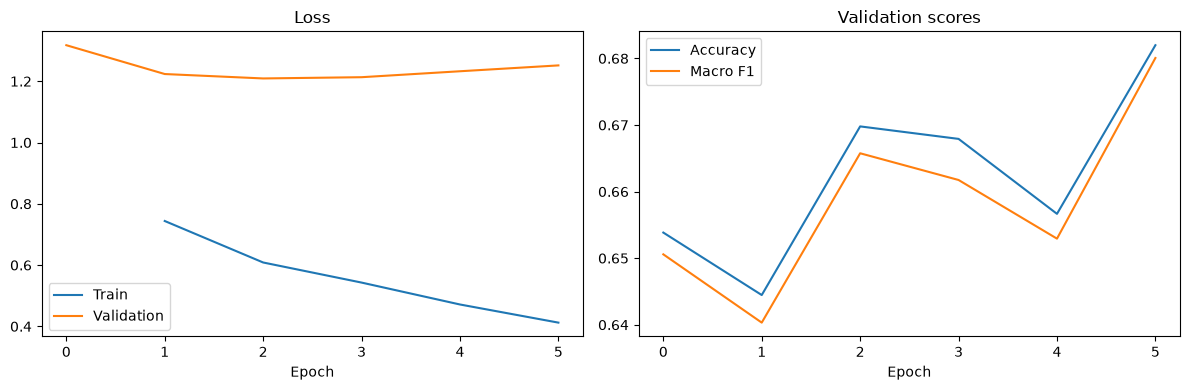

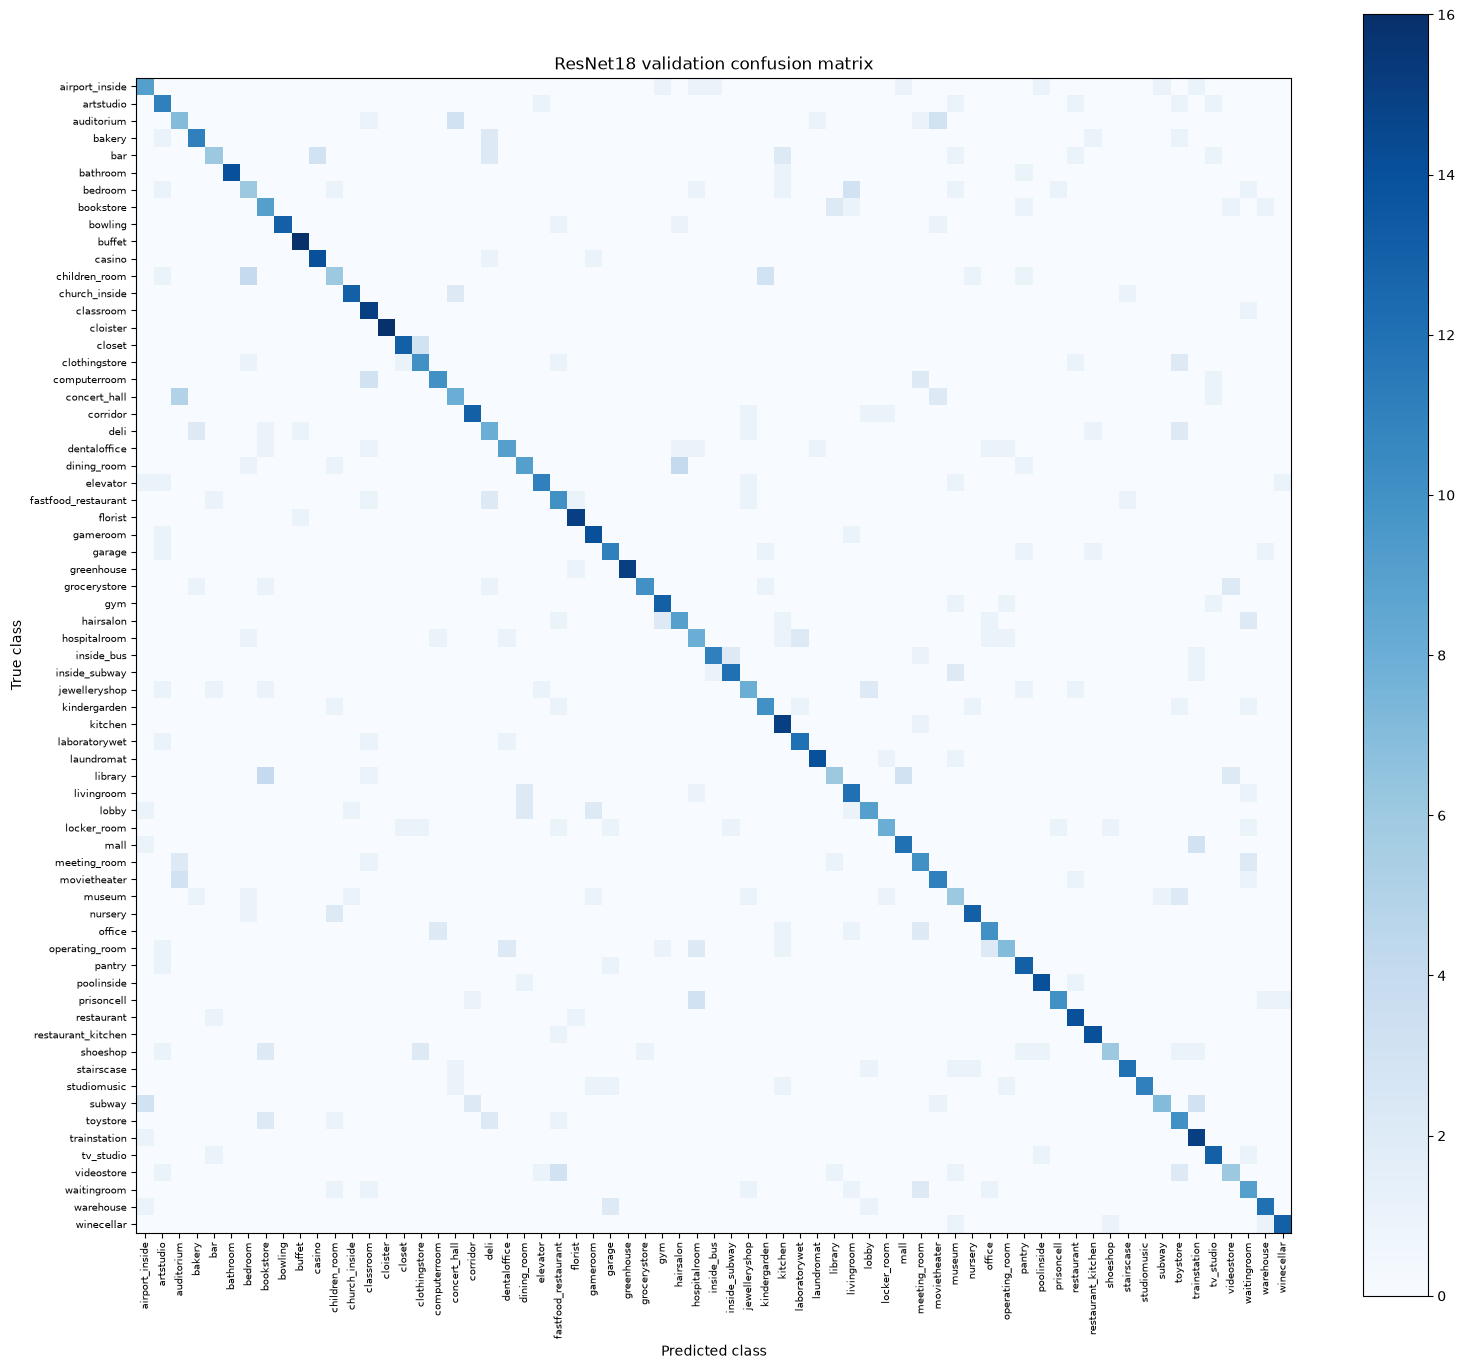

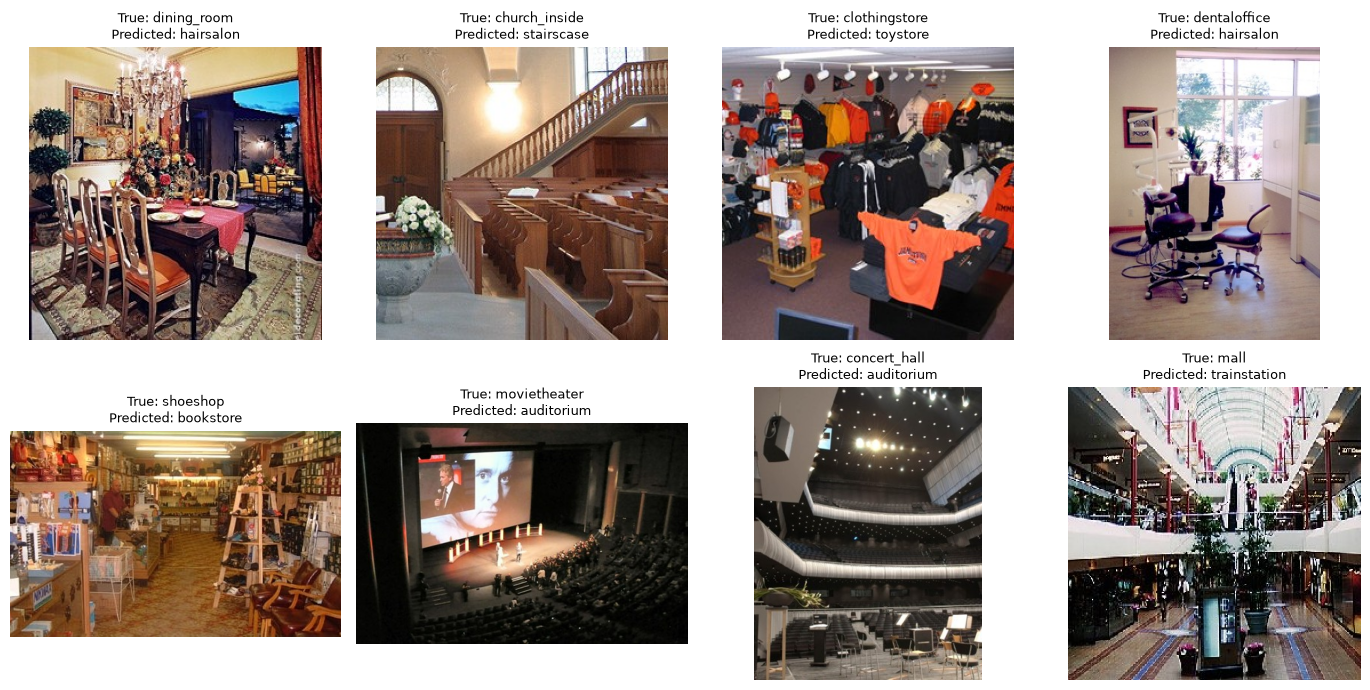

Best model: C:\Users\Spencer\General\daml-aitp\checkpoints\resnet18_low_lr_best.pt
Metrics and predictions: C:\Users\Spencer\General\daml-aitp\experiments


In [13]:
history_df = pd.DataFrame(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
steps = history_df.epoch.to_numpy()
axes[0].plot(steps, history_df.train_loss, label="Train")
axes[0].plot(steps, history_df.val_loss, label="Validation")
axes[0].set(title="Loss", xlabel="Epoch")
axes[0].legend()
axes[1].plot(steps, history_df.val_accuracy, label="Accuracy")
axes[1].plot(steps, history_df.val_macro_f1, label="Macro F1")
axes[1].set(title="Validation scores", xlabel="Epoch")
axes[1].legend()
plt.tight_layout()
plt.show()

cm = confusion_matrix(y_val, y_pred, labels=range(len(class_names)))
fig, ax = plt.subplots(figsize=(16, 14))
plot = ax.imshow(cm, cmap="Blues")
ax.set(xticks=range(len(class_names)), yticks=range(len(class_names)),
       xticklabels=class_names, yticklabels=class_names,
       xlabel="Predicted class", ylabel="True class", title="ResNet18 validation confusion matrix")
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7)
plt.setp(ax.get_yticklabels(), fontsize=7)
fig.colorbar(plot, ax=ax)
plt.tight_layout()
plt.show()

from PIL import Image
errors = predictions.loc[predictions.label != predictions.predicted_label]
if len(errors):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, errors.sample(min(8, len(errors)), random_state=SEED).itertuples()):
        with Image.open(IMAGE_ROOT / row.image_path) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"True: {row.label}\nPredicted: {row.predicted_label}", fontsize=9)
    plt.tight_layout()
    plt.show()
print("Best model:", BEST_PATH)
print("Metrics and predictions:", EXPERIMENT_DIR)

In [14]:
confusions = pd.DataFrame([
    dict(true_label=class_names[i], predicted_label=class_names[j], count=int(cm[i, j]))
    for i in range(len(class_names)) for j in range(len(class_names))
    if i != j and cm[i, j] > 0
]).sort_values("count", ascending=False)
confusions.to_csv(EXPERIMENT_DIR / "resnet18_low_lr_confusions.csv", index=False)
display(confusions.head(15))
original_report_path = EXPERIMENT_DIR / "resnet18_classification_report.csv"
if original_report_path.is_file():
    original_report = pd.read_csv(original_report_path, index_col=0)
    class_comparison = report.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
    class_comparison["original_f1"] = original_report.loc[class_names, "f1-score"]
    class_comparison["f1_change"] = class_comparison["f1-score"] - class_comparison.original_f1
    class_comparison.to_csv(EXPERIMENT_DIR / "resnet18_low_lr_class_comparison.csv")
    display(class_comparison.sort_values("f1_change").head(10))
    display(class_comparison.sort_values("f1_change", ascending=False).head(10))

,true_label,predicted_label,count
64,concert_hall,auditorium,5
48,children_room,bedroom,4
85,dining_room,hairsalon,4
152,library,bookstore,4
206,prisoncell,hospitalroom,3
21,bar,casino,3
229,subway,airport_inside,3
16,auditorium,movietheater,3
232,subway,trainstation,3
154,library,mall,3
